# Parallel-curves test: empirical-Bayes slide effects vs. Harmony (legnini)

Two ways of handling the variation between slides in the same test (Ctrl vs. SHH slides, expression along the distance to SHH+ cells), both on every cell with full-rank ADVI:

1. **Slide effects in the model** (`bin_obs(sample="sample")`, `slide_scales="empirical_bayes"`): a random level and a random curve per slide, with an F reference on `n_slides - 2` denominator degrees of freedom.
2. **Harmony first, no slide effects** (`harmonypy.run_harmony` with `sample` as the batch, on scanpy's PCA): the expression is corrected before the fit, and the model then treats all cells of a condition as one pool.

Each part shows the ranked gene table, a p-value histogram and a volcano plot; the end compares the two.

**Before running:**

* `harmonypy` is needed: `pip install harmonypy` (tested with 2.1.0). It is called directly because `scanpy.external.pp.harmony_integrate` (scanpy 1.12.5) crashes on `harmonypy` 2.x: `Z_corr` changed orientation.
* Both parts cover the whole 88-gene panel with 12 worker processes. On the same data with 4 workers, a slide fit took about 34 min and a fit without slides about 7 min in `comparison_legnini_eb.ipynb`. Shorten `GENES` for a trial run.
* On the cluster, `legnini_eb_vs_harmony.sbatch` runs this notebook and sets the data path through `DIFFSVG_DATA`.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import harmonypy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

As in the morphogen example: cells in the top percentile of SHH expression are the anchor, and every other cell gets its (normalised) distance to the closest SHH+ cell of its slide. Anchors and distances are computed once, before any integration, so both parts test the same cells at the same distances.

In [2]:
adata = sc.read_h5ad(os.environ.get("DIFFSVG_DATA", "/home/lehnerl/Arbeit/data/legnini23.h5ad"))

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
adata.obsm["design_matrix"].head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


## Settings

* `LAYER`: the Normal likelihood suits log-transformed data, so both parts start from `log1p_norm`.
* `TAU`: the smallest shape difference that counts for the parallel-curves test (slope-equivalent units). With `TAU > 0` genes whose shape difference is clearly below it get p-values near 1, so the histogram has a second peak there by design.
* `N_PCS`: the principal components Harmony corrects (scanpy's default of 50).

In [3]:
LAYER = "log1p_norm"
HARMONY_LAYER = f"{LAYER}_harmony"
GENES = list(adata.var_names)  # shorten for a trial run
N_WORKERS = 12
TAU = 0.1
N_PCS = 50
timings = {}

In [4]:
def rank_table(stats, columns):
    """Genes ordered by p-value, ties (e.g. p-values that underflow to 0) broken by the larger statistic."""
    table = stats.sort_values(["parallel_pval", "parallel_stat"], ascending=[True, False])[columns].copy()
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    return table


def qc_plots(stats, title):
    """p-value histogram next to the volcano plot."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    dvg.pl.plot_pvalue_histogram(stats, ax=axes[0])
    dvg.pl.plot_volcano(stats, ax=axes[1], n_label=15)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


PARALLEL_COLUMNS = [
    "shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high",
    "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral", "vi_khat", "vi_ess",
]  # fmt: skip

## 1. Empirical-Bayes slide effects

`sample="sample"` adds a random level and a random curve per slide (every slide belongs to one condition; `slide1_A2-2` has no anchor cells and drops out). The two scales are estimated per gene (`sample_level_sd`, `sample_curve_sd`) and then held fixed while ADVI fits the rest.

With ~200 parameters per gene the importance-sampling share `vi_ess` is lower even for a good approximation, so here `vi_ess > 0.1` together with `vi_khat < 0.7` is the check.

In [5]:
t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None, sample="sample"
)
eb_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    slide_scales="empirical_bayes", test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["1: EB slide effects"] = time.perf_counter() - t0
print(f"{timings['1: EB slide effects']:.0f} s")
eb_stats["vi_trusted"] = (eb_stats["vi_khat"] < 0.7) & (eb_stats["vi_ess"] > 0.1)
print(f"{eb_stats['vi_trusted'].sum()} of {len(eb_stats)} genes pass the variational diagnostics")
eb_table = rank_table(
    eb_stats, [*PARALLEL_COLUMNS, "sample_level_sd", "sample_curve_sd", "parallel_df_denominator", "vi_trusted"]
)
eb_table.head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [04:09<6:01:49, 249.53s/it]

Fitting DiffSVG models:   2%|▏         | 2/88 [04:11<2:28:38, 103.70s/it]

Fitting DiffSVG models:   3%|▎         | 3/88 [04:12<1:20:24, 56.76s/it] 

Fitting DiffSVG models:   5%|▍         | 4/88 [04:13<48:37, 34.73s/it]  

Fitting DiffSVG models:   6%|▌         | 5/88 [04:29<38:57, 28.17s/it]

... (80 outputs left out)

Fitting DiffSVG models: 100%|██████████| 88/88 [18:12<00:00, 14.10s/it]

Fitting DiffSVG models: 100%|██████████| 88/88 [18:12<00:00, 12.41s/it]

1096 s
88 of 88 genes pass the variational diagnostics


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,sample_level_sd,sample_curve_sd,parallel_df_denominator,vi_trusted
gene,,,,,,,,,,,,,,,
HHIP,1,1.383929,0.910924,0.638617,1.184634,138.587858,0.000101,0.008260,-0.085208,0.097713,0.404063,0.110451,0.277793,14,True
FOXA2,2,0.812903,0.398578,0.182974,0.615921,151.363062,0.000188,0.008260,0.006869,0.090688,0.365969,0.044484,0.220541,14,True
GLI1,3,1.172934,0.832966,0.587909,1.079224,114.282182,0.000407,0.009571,0.276354,0.148710,0.429854,0.096918,0.247893,14,True
PAX7,4,1.485805,-0.905373,-1.289125,-0.512397,93.094307,0.000435,0.009571,-2.115028,0.231867,0.227903,0.207073,0.407721,14,True
NEUROG2,5,1.084901,0.370091,0.060921,0.679444,66.907812,0.002818,0.049594,0.635596,0.211027,0.441418,0.224720,0.313438,14,True
PTCH1,6,1.236054,0.180200,-0.235085,0.597429,46.780083,0.008887,0.118677,0.145253,0.160078,0.370631,0.337613,0.434458,14,True
MSX2,7,0.608092,-0.538885,-0.653635,-0.424897,116.864777,0.009440,0.118677,-0.449460,-0.009080,0.495972,0.146334,0.110829,14,True
FOXA1,8,0.404139,0.193341,0.039602,0.348744,85.321934,0.025010,0.275107,-0.019739,0.241805,0.251560,0.029723,0.158258,14,True
DBX2,9,0.974715,0.632142,0.321030,0.946721,39.805485,0.030812,0.301272,-0.320880,0.172355,0.364832,0.161886,0.321363,14,True


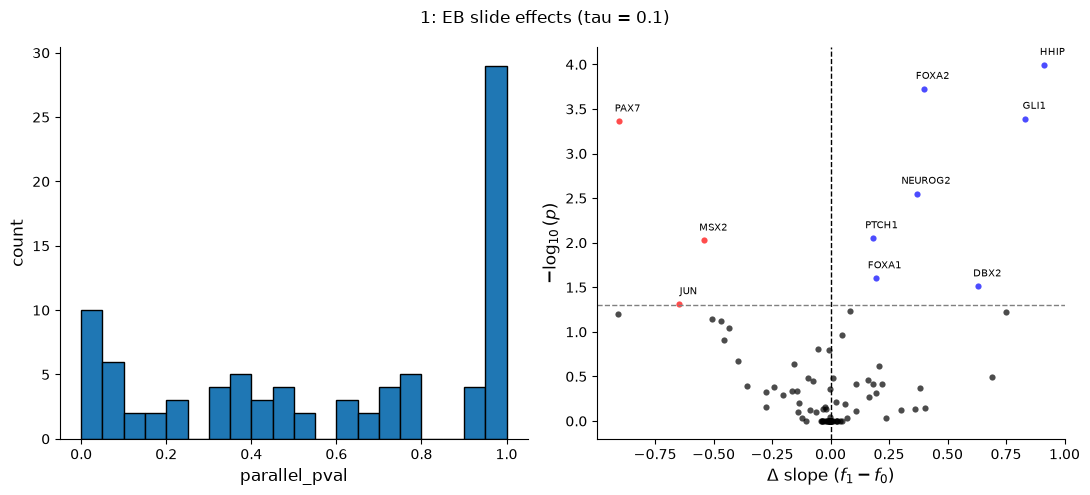

In [6]:
qc_plots(eb_stats, f"1: EB slide effects (tau = {TAU})");

## 2. Harmony, then no slide effects

### Integration

Harmony corrects the PCA embedding (`X_pca_harmony`), not the genes, and the curve test needs genes. So the correction is mapped back through the loadings, `X_corrected = X + (Z_harmony - Z) PCs^T`. Everything outside the corrected components stays as it was, and with `Z_harmony = Z` the data come back unchanged. The result is no longer a sparse log-count matrix (values can be negative), which the Normal likelihood accepts.

In [7]:
t0 = time.perf_counter()
sc.pp.pca(adata, n_comps=N_PCS, layer=LAYER, mask_var=None)
adata.obsm["X_pca_harmony"] = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "sample").Z_corr

X = adata.layers[LAYER]
X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
correction = adata.obsm["X_pca_harmony"] - adata.obsm["X_pca"]
adata.layers[HARMONY_LAYER] = X + correction @ adata.varm["PCs"].T
timings["2a: PCA + Harmony"] = time.perf_counter() - t0
print(f"{timings['2a: PCA + Harmony']:.0f} s; {N_PCS} PCs hold {adata.uns['pca']['variance_ratio'].sum():.1%} of the variance")

2026-11-06 13:58:58,260 - harmonypy - INFO - Running Harmony


2026-11-06 13:58:58,261 - harmonypy - INFO -   Parameters:


2026-11-06 13:58:58,262 - harmonypy - INFO -     max_iter_harmony: 10


2026-11-06 13:58:58,263 - harmonypy - INFO -     max_iter_kmeans: 4


2026-11-06 13:58:58,264 - harmonypy - INFO -     epsilon_cluster: 0.001


2026-11-06 13:58:58,264 - harmonypy - INFO -     epsilon_harmony: 0.01


... (12 outputs left out)

2026-11-06 13:58:58,755 - harmonypy - INFO - Iteration 2 of 10


2026-11-06 13:58:58,880 - harmonypy - INFO - Iteration 3 of 10


2026-11-06 13:58:59,007 - harmonypy - INFO - Converged after 3 iterations


6 s; 50 PCs hold 95.6% of the variance


### What the integration changed

Every slide belongs to one condition, so Harmony cannot tell a slide difference from a condition difference: aligning the slides also pulls the two conditions together. This check shows how much of each was removed, for every gene: the spread of the slide means, and the SHH minus Ctrl gap of the condition means. Keep the shrinking gap in mind when reading part 2 and the comparison.

In [8]:
def slide_spread_and_gap(values):
    """Per gene: the SD of the slide means, and the SHH minus Ctrl difference of the condition means."""
    frame = pd.DataFrame(values, index=adata.obs_names, columns=adata.var_names)
    spread = frame.groupby(adata.obs["sample"].astype(str).to_numpy()).mean().std()
    means = frame.groupby(adata.obs["condition"].astype(str).to_numpy()).mean()
    return spread, means.loc["SHH"] - means.loc["Ctrl"]


spread, gap = slide_spread_and_gap(X)
spread_harmony, gap_harmony = slide_spread_and_gap(adata.layers[HARMONY_LAYER])
print(f"Median SD of the slide means: {spread.median():.3f} before, {spread_harmony.median():.3f} after")
print(f"Condition gap after vs. before, slope over all genes: {np.polyfit(gap, gap_harmony, 1)[0]:.2f}")
pd.DataFrame({"gap before": gap, "gap after": gap_harmony}).loc[gap.abs().nlargest(10).index].round(2)

Median SD of the slide means: 0.122 before, 0.070 after
Condition gap after vs. before, slope over all genes: 0.64


,gap before,gap after
PAX7,-2.18,-1.04
NKX6.1,2.06,1.67
Circ.RMST,-1.34,-0.77
IRX3,-1.27,-0.75
GLI3,-0.78,-0.54
NEUROG2,0.67,0.44
GLI2,-0.57,-0.34
NKX6.2,0.49,0.32
MSX2,-0.46,-0.20
PTPRZ1,-0.44,-0.35


### Test

The same call as for pooled cells without integration, on the corrected layer. There are no slide terms, so all cells of a condition count as independent observations and the p-value has no slide-level denominator. Harmony's correction is taken as known, so its uncertainty does not reach the p-values. `vi_khat` (below ~0.7) and `vi_ess` (above ~0.5) check the approximation.

In [9]:
t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", genes=GENES, layer=HARMONY_LAYER, n_bins=50, window_radius=None
)
harmony_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["2b: Harmony layer, no slides"] = time.perf_counter() - t0
print(f"{timings['2b: Harmony layer, no slides']:.0f} s")
harmony_stats["vi_trusted"] = (harmony_stats["vi_khat"] < 0.7) & (harmony_stats["vi_ess"] > 0.5)
print(f"{harmony_stats['vi_trusted'].sum()} of {len(harmony_stats)} genes pass the variational diagnostics")
harmony_table = rank_table(harmony_stats, [*PARALLEL_COLUMNS, "vi_trusted"])
harmony_table.head(25)

Fitting DiffSVG models:   0%|          | 0/88 [00:00<?, ?it/s]

Fitting DiffSVG models:   1%|          | 1/88 [00:51<1:14:48, 51.60s/it]

Fitting DiffSVG models:   6%|▌         | 5/88 [00:51<10:41,  7.73s/it]  

Fitting DiffSVG models:   8%|▊         | 7/88 [00:52<06:35,  4.88s/it]

/ictstr01/groups/ml01/workspace/laurens.lehner/tools/apps/miniforge/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting DiffSVG models:   8%|▊         | 7/88 [01:02<06:35,  4.88s/it]

... (69 outputs left out)

Fitting DiffSVG models: 100%|██████████| 88/88 [03:43<00:00,  2.54s/it]

224 s
85 of 88 genes pass the variational diagnostics



/tmp/ipykernel_3738554/1586358918.py:5: UserWarning: 3 of 88 genes fail the variational diagnostics (expected: vi_khat < 0.7 and vi_ess > 0.5), so the approximation does not match the posterior for them: do not read their p-values.
  harmony_stats, _, _ = dvg.tl.fit_model(


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,vi_trusted
gene,,,,,,,,,,,,
PAX7,1,1.393387,-1.013658,-1.063682,-0.965944,4724.948739,0.000000e+00,0.000000e+00,-1.051880,0.228101,0.772791,True
HHIP,2,1.156496,0.746711,0.686740,0.804289,2551.043094,0.000000e+00,0.000000e+00,0.094027,0.227521,0.782828,True
GLI1,3,1.086592,0.744107,0.684978,0.800905,2377.817547,0.000000e+00,0.000000e+00,0.214868,0.227663,0.782143,True
FOS,4,0.895472,-0.508927,-0.574520,-0.446030,1462.957641,8.493075e-239,1.868476e-237,-0.187517,0.241917,0.787471,True
JUN,5,1.325245,-0.736521,-0.838842,-0.637955,1295.356508,7.664775e-232,1.349000e-230,-0.297414,0.150488,0.811752,True
PTCH1,6,1.275156,0.314232,0.222390,0.402525,1318.755865,2.388387e-231,3.502968e-230,0.009856,0.157077,0.805779,True
DBX2,7,0.758688,0.309366,0.246494,0.369645,1420.055048,1.119248e-227,1.407055e-226,-0.458165,0.225461,0.785235,True
AC129492.1,8,1.033605,-0.789254,-0.868948,-0.712694,1326.433158,2.227016e-225,2.449718e-224,-0.304319,0.201960,0.798037,True
DBX1,9,0.948758,0.449240,0.369389,0.525950,1284.386904,2.024829e-217,1.979833e-216,-0.368106,0.201609,0.798146,True


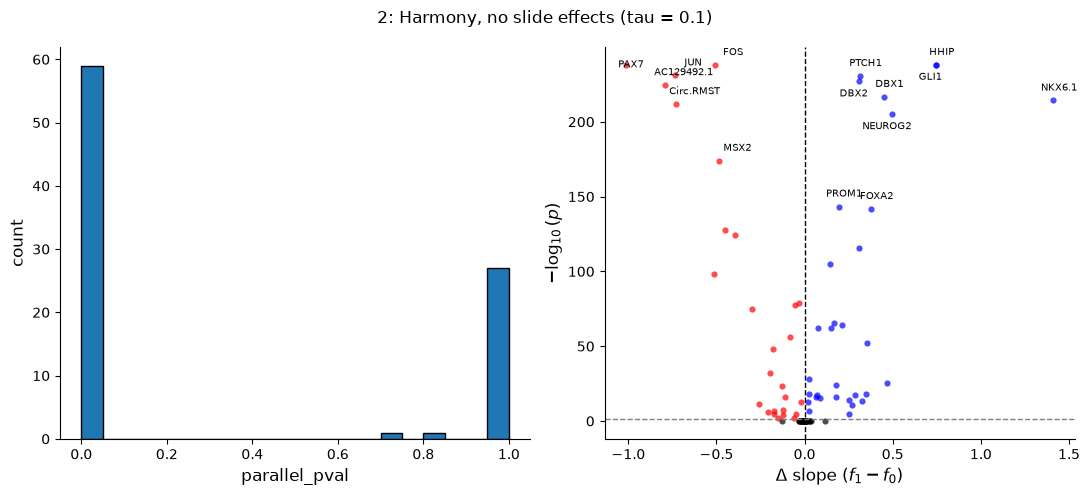

In [10]:
qc_plots(harmony_stats, f"2: Harmony, no slide effects (tau = {TAU})");

## Comparison

How many genes each approach calls, the correlation between the two (ranks, effect sizes, significance) and the overlap of their top 20. The p-values come from different reference distributions, so compare the calls with that in mind. Without slide terms they can underflow to 0; those are floored at 1e-300 here, which affects the `-log10 p` correlation. The statistic `parallel_stat` needs no floor.

In [11]:
NAMES = {"eb": "1: EB slide effects", "harmony": "2: Harmony"}
STATS = {"eb": eb_stats, "harmony": harmony_stats.loc[eb_stats.index]}
FLOOR = 1e-300  # p-values can underflow to 0


def minus_log10_p(stats):
    return -np.log10(stats["parallel_pval"].clip(lower=FLOOR))


display(
    pd.DataFrame(
        {
            NAMES[key]: {
                "p < 0.05": int((stats["parallel_pval"] < 0.05).sum()),
                "BH-adjusted < 0.05": int((stats["parallel_pval_adj"] < 0.05).sum()),
            }
            for key, stats in STATS.items()
        }
    )
)

quantities = {
    "rank": (eb_table["rank"].loc[eb_stats.index], harmony_table["rank"].loc[eb_stats.index]),
    "shape_diff": (STATS["eb"]["shape_diff"], STATS["harmony"]["shape_diff"]),
    "slope_diff": (STATS["eb"]["slope_diff"], STATS["harmony"]["slope_diff"]),
    "parallel_stat": (STATS["eb"]["parallel_stat"], STATS["harmony"]["parallel_stat"]),
    "-log10 p": (minus_log10_p(STATS["eb"]), minus_log10_p(STATS["harmony"])),
}
print("Correlation between the two approaches, over all genes")
display(
    pd.DataFrame(
        {
            name: {"Pearson": a.corr(b), "Spearman": a.corr(b, method="spearman")}
            for name, (a, b) in quantities.items()
        }
    ).round(3)
)

top_eb = set(eb_table.index[:20])
top_harmony = set(harmony_table.index[:20])
print(f"Overlap of the top 20 genes: {len(top_eb & top_harmony)}")
print("Only in the EB top 20:", ", ".join(sorted(top_eb - top_harmony)))
print("Only in the Harmony top 20:", ", ".join(sorted(top_harmony - top_eb)))

pd.Series(timings, name="seconds").round(0).to_frame()

,1: EB slide effects,2: Harmony
p < 0.05,10,59
BH-adjusted < 0.05,5,59


Correlation between the two approaches, over all genes


,rank,shape_diff,slope_diff,parallel_stat,-log10 p
Pearson,0.916,0.950,0.936,0.678,0.828
Spearman,0.916,0.981,0.965,0.647,0.912


Overlap of the top 20 genes: 16
Only in the EB top 20: FOXA1, PER2, POLR1B, SHH
Only in the Harmony top 20: IRX3, MAP2, NKX6.1, TUBB3


,seconds
1: EB slide effects,1096.0
2a: PCA + Harmony,6.0
"2b: Harmony layer, no slides",224.0


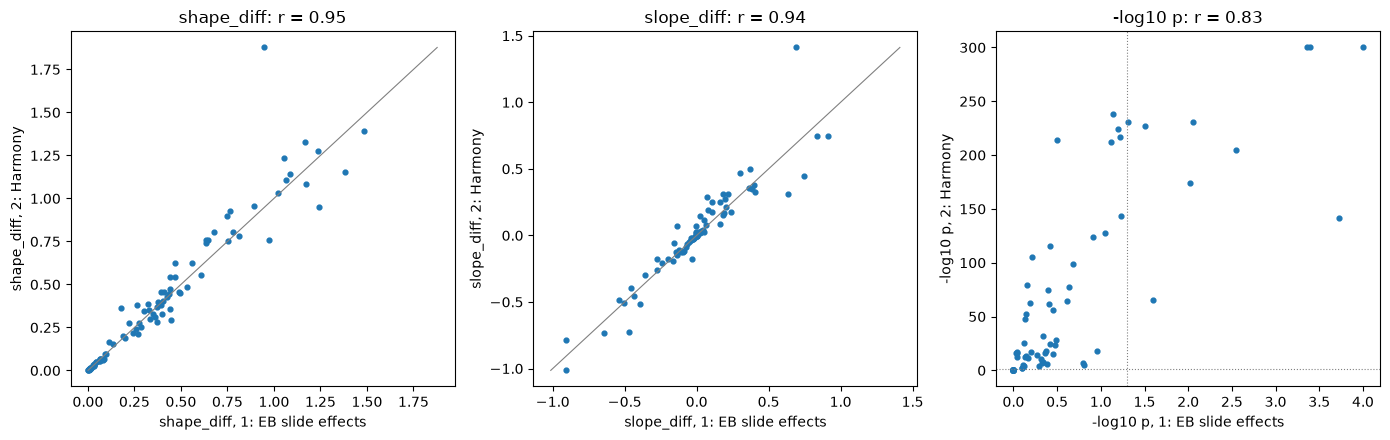

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, name in zip(axes, ["shape_diff", "slope_diff", "-log10 p"], strict=True):
    a, b = quantities[name]
    ax.scatter(a, b, s=12)
    if name != "-log10 p":  # the two p-values differ too much in scale for a diagonal to mean anything
        low, high = float(min(a.min(), b.min())), float(max(a.max(), b.max()))
        ax.plot([low, high], [low, high], color="grey", lw=0.8)
    ax.set(xlabel=f"{name}, {NAMES['eb']}", ylabel=f"{name}, {NAMES['harmony']}", title=f"{name}: r = {a.corr(b):.2f}")
axes[2].axhline(-np.log10(0.05), color="grey", lw=0.8, ls=":")
axes[2].axvline(-np.log10(0.05), color="grey", lw=0.8, ls=":")
fig.tight_layout()